# Phase 1 – Part B: Supervised Learning

## Logistic Regression

### 1. Model Selection Rationale
Logistic Regression was selected as a baseline model because the problem is a binary classification task. It is simple, computationally efficient, and easy to interpret.

### 2. Data Preparation
The preprocessed and scaled training and testing datasets were used. The target variable is `Diabetes_binary`.

### 3. Model Training

In [1]:
import pandas as pd

train_df = pd.read_csv("../Dataset/train_data_scaled.csv")
test_df = pd.read_csv("../Dataset/test_data_scaled.csv")

train_df.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1.0,1.0,1.0,1.522681,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,1.023248,2.085779,0.795089,0.0,0.0,-0.560250,0.096651,0.620802,1.0
1,1.0,1.0,1.0,2.574384,1.0,0.0,1.0,0.0,1.0,1.0,...,1.0,0.120930,3.179636,0.795089,1.0,0.0,-0.910212,-1.848155,-2.132254,1.0
2,0.0,0.0,1.0,-0.881209,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,-0.781388,-0.101935,-0.585930,0.0,0.0,-0.560250,0.096651,0.620802,0.0
3,1.0,1.0,1.0,1.823168,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.120930,-0.466554,-0.585930,0.0,0.0,0.139674,0.096651,0.620802,1.0
4,0.0,0.0,1.0,0.771466,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.120930,0.262684,-0.585930,1.0,0.0,0.139674,0.096651,0.161959,1.0


In [3]:
X_train = train_df.drop("Diabetes_binary", axis=1)
y_train = train_df["Diabetes_binary"]

X_test = test_df.drop("Diabetes_binary", axis=1)
y_test = test_df["Diabetes_binary"]

In [4]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [5]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

### 4. Model Evaluation
The model was evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, and the Confusion Matrix.

In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7457283521575442
Precision: 0.7384448069603046
Recall: 0.7737891737891738
F1-score: 0.7557039510294936
ROC-AUC: 0.8183713494005013

Classification Report:
              precision    recall  f1-score   support

         0.0       0.75      0.72      0.73      6792
         1.0       0.74      0.77      0.76      7020

    accuracy                           0.75     13812
   macro avg       0.75      0.75      0.75     13812
weighted avg       0.75      0.75      0.75     13812


Confusion Matrix:
[[4868 1924]
 [1588 5432]]


### 5. Cross-Validation
A 5-fold cross-validation was applied to evaluate model stability across different subsets of the training data.

In [7]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

cv_model = LogisticRegression(max_iter=1000, random_state=42)

scores = cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("F1 scores:", scores)
print("Mean F1:", scores.mean())

F1 scores: [0.76134878 0.74704656 0.75772613 0.75434764 0.75447637]
Mean F1: 0.7549890958827129


### 6. Hyperparameter Tuning
GridSearchCV was used to tune the `C` and `solver` hyperparameters.

In [8]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"]
}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid,
    cv=5,
    scoring="f1"
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

Best Parameters: {'C': 0.1, 'solver': 'lbfgs'}
Best CV F1: 0.7550670350821151


### Hyperparameter Tuning Results

GridSearchCV identified `C = 0.1` and `solver = lbfgs` as the best hyperparameter combination based on the F1-score.

The best cross-validation F1-score was approximately 0.755. This result is very close to the baseline model performance, indicating that hyperparameter tuning did not significantly improve the Logistic Regression model.

In [9]:
best_model = grid.best_estimator_

y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

### Tuned Model Evaluation

In [13]:
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1-score:", f1_score(y_test, y_pred_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))

Accuracy: 0.7456559513466551
Precision: 0.7383444338725024
Recall: 0.7737891737891738
F1-score: 0.755651387633025
ROC-AUC: 0.8183975659314293


The tuned model achieved performance almost identical to the baseline model. The F1-score remained approximately 0.756 and the ROC-AUC remained approximately 0.818. This suggests that the baseline Logistic Regression model was already stable and not highly sensitive to the tested hyperparameters.

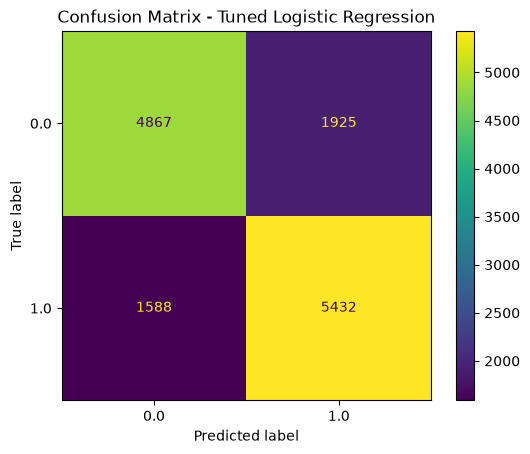

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned
)

plt.title("Confusion Matrix - Tuned Logistic Regression")
plt.show()

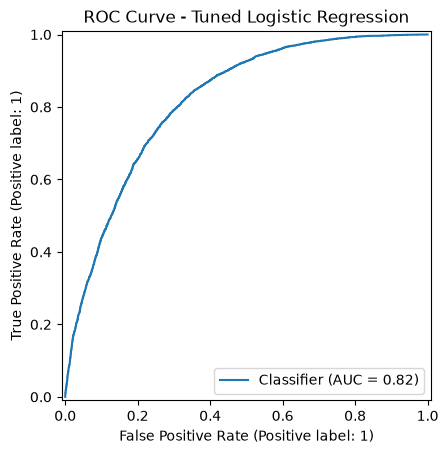

In [12]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_tuned
)

plt.title("ROC Curve - Tuned Logistic Regression")
plt.show()

The tuned Logistic Regression model achieved an accuracy of approximately 74.6%, an F1-score of 75.6%, and an ROC-AUC of 81.8%. The confusion matrix shows that the model correctly classified 4,867 negative cases and 5,432 positive cases. However, it produced 1,588 false negatives and 1,925 false positives. In a healthcare screening context, false negatives are particularly important because they represent positive cases that were missed by the model. The ROC curve and AUC value indicate that the model has a good ability to distinguish between the two classes.

Strengths: Simple, fast, interpretable, and suitable as a baseline model for binary classification.
Limitations: May not capture complex non-linear relationships between health indicators as effectively as tree-based models such as Random Forest or XGBoost.